# 08B.4 — Incremental Combine movement information

**Objective O4 — additional information.** Which measured characteristics remain distinguishable, interpretable and repeatable **after the information already captured by official tests is accounted for** — whether or not they predict anything in the NFL?

This notebook is independent of the football-outcome branch: it runs when football transfer is frozen, exploratory or blocked. It reads **no NFL value**.

**Frozen candidates only** (the feature atlas is not reopened): tracked p95 speed · time from 4 to 8 yd/s · the two graded speed-band measures of family F6 · FPCA scores · the TCN-B fingerprint.

**Method.**

1. *Stopwatch adjustment, cross-fitted.* The athlete's expected value from position, official forty, official 10-yard split, weight and height is fitted on the athletes of the **other** folds. The residual of an attempt is the attempt minus that expectation.
2. *Repeatability, raw and residual.* Scalars: ICC(1) of repeated attempts within position, athlete bootstrap. Embeddings: repeat-attempt retrieval AUC within position on the **inductive** embeddings (the fold encoder that never saw the athlete); 0.5 = chance. No embedding dimension is given a physical meaning.
3. *Sensitivity.* Recordings without a signal flag, each position group, each draft cohort.
4. *Matched stopwatch prospects.* How often two athletes with near-identical official results differ by more than the measurement error of both.
5. *Scouting evidence registry.* One row per characteristic with the fields a scout needs. The status comes from an ordered rule — no weighted novelty score.

**Prerequisites (same `RUN_MODE`).** 00, 01, 02, 04A; 06B and 06C when available (embeddings and matched pairs); 06B / 08B.2 tables are read only to fill the *NFL predictive evidence* column.

In [1]:
RUN_MODE = 'full'             # 'smoke' | 'full'
SEED = 20261011
FORCE_REBUILD = False
SAVE_TABLES = True
SAVE_FIGURES = True
NUM_WORKERS = 0
EXPERIMENT_VERSION = '08B4.1'
BOOTSTRAP_ITERATIONS = 500    # athlete bootstrap of every repeatability estimate
M06_PRIMARY_TARGET = 'O2.accel_sust05_mean'   # frozen primary NFL movement target of Milestone 05 (read only, for the evidence column)
SHOW_TABLES = True

In [2]:
from nflbdb.data.config import Phase01Config, configure_runtime

cfg = Phase01Config.load()
configure_runtime(cfg)

import time
from dataclasses import replace

import numpy as np
import polars as pl
from IPython.display import Markdown, display

from nflbdb.data.utils import utc_now
from nflbdb.research.advanced_movement import atlas as at
from nflbdb.research.advanced_movement import checkpoint as ck
from nflbdb.research.advanced_movement import config as amc
from nflbdb.research.advanced_movement import data as amd
from nflbdb.research.advanced_movement import football_figures as ff
from nflbdb.research.advanced_movement import football_registry as fr
from nflbdb.research.advanced_movement import football_transfer as ft
from nflbdb.research.advanced_movement import football_validation as fv
from nflbdb.research.advanced_movement import movement_information as mi
from nflbdb.research.advanced_movement import sequences as seq
from nflbdb.research.advanced_movement import transfer_models as tm
from nflbdb.research.advanced_movement import transfer_robust as tx
from nflbdb.research.advanced_movement.artifacts import FootballStore, MissingArtifactError
from nflbdb.research.advanced_movement.scoring import figures as sfig
from nflbdb.research.advanced_movement.scoring.scorecards import assert_no_nfl_columns

controls = amc.NotebookControls(run_mode=RUN_MODE, force_rebuild=FORCE_REBUILD, save_figures=SAVE_FIGURES, save_tables=SAVE_TABLES,
                                seed=SEED, num_workers=NUM_WORKERS).validate()
acfg = amc.AdvancedConfig().for_mode(controls)
icfg = mi.InfoConfig().for_mode(controls)
if not controls.smoke:
    icfg = replace(icfg, n_boot=BOOTSTRAP_ITERATIONS)
store = FootballStore(cfg, controls)
up, T = store.upstream, store.transfer
amc.seed_everything(controls.seed)
NB = {'00': '00_research_setup_and_data_audit.ipynb', '01': '01_sequence_eda_and_alignment.ipynb', '02': '02_functional_pca_baseline.ipynb',
      '04A': '04a_feature_characteristic_atlas.ipynb', '06B': '06b_combine_to_nfl_transfer_benchmark.ipynb',
      '06C': '06c_transfer_robustness_and_scouting_insights.ipynb', '08B4': '08b4_incremental_movement_information.ipynb'}

def optional(fn, what):
    try:
        return fn()
    except MissingArtifactError as e:
        print(f'OPTIONAL INPUT ABSENT — {what}: {e}')
        return None

# ---- Combine-side inputs (no NFL value)
athletes = up.require(amd.ATHLETES, NB['00'])
windows = up.require(ck.WINDOWS, NB['02'])
attempt_values = store.atlas.require(at.ATTEMPT_VALUES, NB['04A'])
fdict = store.atlas.require(at.DICTIONARY, NB['04A'])
frames = optional(lambda: up.require(seq.SEQ_FRAMES, NB['01']), 'sequence frames (speed-curve figure)')
rep = optional(lambda: T.require_named('transfer_attempt_representations_outer', NB['06B']), 'fold-fitted FPCA / TCN representations of 06B')
pairs06 = optional(lambda: T.require(tx.PAIRS, NB['06C']), 'matched stopwatch pairs of 06C')
if all(c in athletes.columns for c in mi.COVARIATES):
    src = athletes
else:
    mart = amd.AdvInputs(cfg, acfg).mart().filter(pl.col('nfl_id').is_in(athletes['nfl_id'].to_list()))
    src = athletes.select('nfl_id', 'position_group', 'draft_year').join(at.official_table(mart, athletes).select('nfl_id', *mi.COVARIATES), on='nfl_id', how='left')
roster = src.select('nfl_id', 'position_group', pl.col('draft_year').cast(pl.Int64), *[pl.col(c).cast(pl.Float64) for c in mi.COVARIATES])
assert_no_nfl_columns(roster, 'roster')
ORDER = dict(zip(windows['seq_id'].to_list(), windows['attempt_order'].to_list()))
QUALITY_OK = set(windows.filter(pl.col('S2_signal'))['seq_id'].to_list())      # S2_signal = the recording carries no signal-quality flag
R = mi.roster_arrays(roster)

FEATURES = mi.prepare(attempt_values, rep, ORDER)
wanted = [s[0] for s in mi.SCALARS] + [e[0] for e in mi.EMBEDDINGS]
ABSENT = [f for f in wanted if f not in {x.feature_id for x in FEATURES}]
LABELS = {f.feature_id: f.label for f in FEATURES}
UNITS = {f.feature_id: f.unit for f in FEATURES}
DEFS = {**{f.feature_id: f.definition for f in FEATURES}, **dict(fdict.filter(pl.col('feature_id').is_in(wanted)).select('feature_id', 'definition').iter_rows())}

PARAMS = {'experiment_version': EXPERIMENT_VERSION, 'info': icfg.params(), 'candidates': [f.feature_id for f in FEATURES], 'covariates': list(mi.COVARIATES)}
PROV = {'notebook': NB['08B4'], **PARAMS, 'run_mode': controls.run_mode, 'seed': controls.seed, 'nfl_inputs': 'none'}
save = lambda df, c: store.write(df, c, '08B4', PROV) if controls.save_tables else df
INPUT_FILES = [store.atlas.parquet(at.ATTEMPT_VALUES), up.parquet(ck.WINDOWS)] + ([T.data_dir / 'transfer_attempt_representations_outer.parquet'] if rep is not None else [])

label = 'SMOKE — wiring check, numbers are not results' if controls.smoke else 'FULL'
display(Markdown(f'**Run mode: `{controls.run_mode}`** ({label}) · {roster.height} Combine athletes · candidates {[f.feature_id for f in FEATURES]} · '
                 f'absent from the persisted tables (skipped, not invented): {ABSENT or "none"} · {len(QUALITY_OK)} recordings without a signal flag'))
display(store.describe())

**Run mode: `full`** (FULL) · 510 Combine athletes · candidates ['F2.forty.p95_speed', 'F6.forty.time_v4_to_v8_s', 'F6.forty.accel_1s_from_v4', 'F6.forty.speed_gain_10yd_from_v4', 'FPCA', 'TCN'] · absent from the persisted tables (skipped, not invented): none · 734 recordings without a signal flag

what,where
str,str
"""run mode""","""full"""
"""tables (CSV)""","""reports/tables/advanced_moveme…"
"""datasets (Parquet + schema sid…","""warehouse/gold/advanced_moveme…"
"""figures (PNG 300 DPI, SVG, PDF…","""reports/figures/advanced_movem…"
"""models and fitted preprocessin…","""artifacts/models/advanced_move…"


## 1 · Synthetic checks

A planted stopwatch-driven feature must come out *repeatable and redundant*; a planted independent repeatable trait must come out *repeatable beyond official tests*; a retrieval AUC is compared with chance; embeddings are read from the held-out fold encoder only.

In [3]:
validation = fv.run_all((fv.check_incremental_information_statuses, fv.check_inductive_representation_compatibility))
with pl.Config(fmt_str_lengths=200, tbl_rows=-1):
    display(validation)
fv.assert_all_passed(validation)

check,status,detail
str,str,str
"""incremental_information_statuses""","""PASS""","""cross-fitted stopwatch adjustment: redundant versus repeatable-beyond-official features are separated; AUC against chance"""
"""inductive_representation_compatibility""","""PASS""","""representations are read from the held-out fold encoder only"""


## 2 · Raw and stopwatch-adjusted repeatability

Status rule (reference lines are heuristics declared in `InfoConfig` before running):

1. fewer than the required athletes with a repeat → `insufficient_support`;
2. raw repeatability below its reference line → `unstable`;
3. residual repeatability whose lower bound does not exceed *nothing* (0 for an ICC, 0.5 for an AUC) → `redundant_with_official`;
4. residual repeatability at its reference line → `repeatable_beyond_official`; otherwise `weak_residual_signal`.

`r2_official` is the cross-fitted share of the variance of athlete means explained by position and official tests. It can be slightly negative when the adjustment does not generalise — that is reported, not clipped.

In [4]:
def _info():
    t0 = time.perf_counter()
    return mi.information_table(FEATURES, R, icfg, progress=lambda m: print(f'[{time.perf_counter() - t0:5.0f} s] {m}'))

stage = store.build('08b4_information', [mi.INFO, mi.RESIDUALS], _info, PARAMS, INPUT_FILES)
info, residuals = stage[mi.INFO.name], stage[mi.RESIDUALS.name]
assert_no_nfl_columns(info, 'information table')
with pl.Config(tbl_rows=-1, tbl_width_chars=260, fmt_str_lengths=150):
    display(info.select('label', 'metric', 'n_athletes', 'n_repeat', 'n_adjusted', 'raw_value', 'raw_lower', 'raw_upper', 'r2_position', 'r2_official',
                        'residual_value', 'residual_lower', 'residual_upper', 'status'))
    display(info.select('feature_id', 'reason'))

23:41:43 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:08b4_information] computing (never run)


[    0 s] F2.forty.p95_speed: 793 attempts · 375 athletes with a repeat · repeatable_beyond_official
[    0 s] F6.forty.time_v4_to_v8_s: 793 attempts · 375 athletes with a repeat · repeatable_beyond_official
[    0 s] F6.forty.accel_1s_from_v4: 793 attempts · 375 athletes with a repeat · unstable
[    0 s] F6.forty.speed_gain_10yd_from_v4: 793 attempts · 375 athletes with a repeat · weak_residual_signal
[    0 s] FPCA: 793 attempts · 375 athletes with a repeat · repeatable_beyond_official


23:41:43 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08b4_information] movement_incremental_information: 6 rows → warehouse/gold/advanced_movement/football_v1/movement_incremental_information.parquet
23:41:43 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08b4_information] movement_official_adjusted_values: 1,672 rows → warehouse/gold/advanced_movement/football_v1/movement_official_adjusted_values.parquet


[    0 s] TCN: 793 attempts · 375 athletes with a repeat · repeatable_beyond_official


label,metric,n_athletes,n_repeat,n_adjusted,raw_value,raw_lower,raw_upper,r2_position,r2_official,residual_value,residual_lower,residual_upper,status
str,str,i64,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,str
"""tracked top speed (p95)""","""ICC(1) within position""",418,375,418,0.9474,0.935868,0.957865,0.739899,0.965205,0.684495,0.619325,0.746694,"""repeatable_beyond_official"""
"""speed development 4 → 8 yd/s""","""ICC(1) within position""",418,375,418,0.821829,0.773767,0.860276,0.651288,0.878748,0.589861,0.49074,0.670501,"""repeatable_beyond_official"""
"""acceleration over 1 s from 4 yd/s""","""ICC(1) within position""",418,375,418,0.669293,0.573594,0.751772,0.662662,0.822638,0.473865,0.341565,0.588648,"""unstable"""
"""speed gain over 10 yd from 4 yd/s""","""ICC(1) within position""",418,375,418,0.806643,0.747761,0.855003,0.729771,0.916959,0.487011,0.384085,0.586396,"""weak_residual_signal"""
"""FPCA speed-curve scores (K = 2)""","""repeat-attempt retrieval AUC within position""",418,375,418,0.777512,0.751481,0.804339,0.73202,0.946167,0.736849,0.715106,0.758284,"""repeatable_beyond_official"""
"""TCN-B movement fingerprint (8-d)""","""repeat-attempt retrieval AUC within position""",418,375,418,0.971818,0.967769,0.975811,0.08852,0.0964,0.980145,0.976043,0.983936,"""repeatable_beyond_official"""


feature_id,reason
str,str
"""F2.forty.p95_speed""","""residual repeatability 0.68 [0.62, 0.75] ≥ 0.50"""
"""F6.forty.time_v4_to_v8_s""","""residual repeatability 0.59 [0.49, 0.67] ≥ 0.50"""
"""F6.forty.accel_1s_from_v4""","""raw repeatability 0.67 below the reference line 0.70"""
"""F6.forty.speed_gain_10yd_from_v4""","""residual repeatability 0.49 [0.38, 0.59] below 0.50"""
"""FPCA""","""residual repeatability 0.74 [0.72, 0.76] ≥ 0.65"""
"""TCN""","""residual repeatability 0.98 [0.98, 0.98] ≥ 0.65"""


## 3 · Sensitivity — recording quality, position, draft cohort — and matched stopwatch prospects

- **Recording quality.** The same analysis on recordings without a signal flag: does the residual repeatability depend on acquisition?
- **Position and cohort.** Heterogeneity and stability. A subset with too few athletes with a repeat gets its counts and no estimate.
- **Matched stopwatch prospects.** Among the pairs frozen in 06C (same position, near-identical forty, 10-yard split and body), the share whose difference in a tracked characteristic exceeds 1.96 × the standard error of the **difference**. About 5 % is expected if the pairs did not differ at all.

In [5]:
sens = save(mi.sensitivity_table(FEATURES, R, icfg, QUALITY_OK), mi.INFO_SENS)
match = save(mi.matched_distinguishability(residuals, pairs06, UNITS), mi.MATCH_DIST) if pairs06 is not None else mi.MATCH_DIST.empty()
if SHOW_TABLES:
    with pl.Config(tbl_rows=-1, tbl_width_chars=240, fmt_str_lengths=100):
        display(sens)
        display(match)

23:41:44 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08B4] movement_information_sensitivity: 54 rows → warehouse/gold/advanced_movement/football_v1/movement_information_sensitivity.parquet
23:41:44 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08B4] movement_matched_distinguishability: 4 rows → warehouse/gold/advanced_movement/football_v1/movement_matched_distinguishability.parquet


feature_id,subset_kind,subset,n_athletes,n_repeat,raw_value,residual_value,residual_lower,residual_upper,note
str,str,str,i64,i64,f64,f64,f64,f64,str
"""F2.forty.p95_speed""","""recording_quality""","""no signal flag""",401,333,0.948433,0.655019,0.570862,0.715301,""""""
"""F2.forty.p95_speed""","""position_group""","""DB""",102,93,0.916072,0.789677,0.706683,0.85075,""""""
"""F2.forty.p95_speed""","""position_group""","""DL""",93,84,0.975886,0.549725,0.412568,0.693273,""""""
"""F2.forty.p95_speed""","""position_group""","""OL""",95,84,0.932526,0.495649,0.317465,0.638762,""""""
"""F2.forty.p95_speed""","""position_group""","""TE""",34,32,0.923369,0.776403,0.472359,0.89965,""""""
"""F2.forty.p95_speed""","""position_group""","""WR""",94,82,0.893865,0.745364,0.600183,0.828552,""""""
"""F2.forty.p95_speed""","""draft_cohort""","""2023""",138,124,0.956033,0.668832,0.553045,0.757456,""""""
"""F2.forty.p95_speed""","""draft_cohort""","""2024""",147,122,0.93053,0.613558,0.497449,0.699832,""""""
"""F2.forty.p95_speed""","""draft_cohort""","""2025""",133,129,0.94706,0.730722,0.63172,0.801964,""""""


feature_id,unit,n_pairs,n_athletes,median_abs_difference,median_se_difference,share_distinguishable
str,str,i64,i64,f64,f64,f64
"""F2.forty.p95_speed""","""yd/s""",833,275,0.182152,0.089088,0.494598
"""F6.forty.accel_1s_from_v4""","""yd/s²""",833,275,0.188422,0.186659,0.198079
"""F6.forty.speed_gain_10yd_from_v4""","""yd/s""",833,275,0.143411,0.120335,0.2509
"""F6.forty.time_v4_to_v8_s""","""s""",833,275,0.082871,0.076057,0.218487


## 4 · Scouting evidence registry

One row per characteristic: physical definition · reference position · raw repeatability · residual repeatability · stopwatch redundancy · measurement quality · coverage · **NFL predictive evidence** · practical interpretation · limitations · status.

The *NFL predictive evidence* column is read from **executed** transfer tables only: the Milestone 06 comparison of the model carrying the characteristic, and the 08B.2 comparison when that notebook ran. A characteristic that was not tested as a separate model says so.

In [6]:
nfl_evidence = {}
m06 = optional(lambda: T.require(tm.PAIRED, NB['06B']), 'Milestone 06 paired comparisons (evidence column)')
if m06 is not None:
    m06p = m06.filter((pl.col('analysis') == 'primary') & (pl.col('cohort') == 'primary') & (pl.col('metric') == 'delta_rmse') & (pl.col('reference') == 'M1')
                      & (pl.col('target_id') == M06_PRIMARY_TARGET))
    for fid, model in mi.M06_MODEL.items():
        r = m06p.filter(pl.col('model') == model)
        if r.height:
            r = r.row(0, named=True)
            nfl_evidence[fid] = (f'Milestone 06, NFL sustained acceleration, {model} vs M1, n = {r["n_athletes"]}: Δ RMSE {r["estimate"]:+.4f} '
                                 f'[{r["ci_lower"]:+.4f}, {r["ci_upper"]:+.4f}] — ' + ('interval above 0' if r['established'] else 'not established'))
FOOTBALL_HYP = store.read(ft.HYP) if store.exists(ft.HYP) else None
if FOOTBALL_HYP is not None:
    for fid, model in mi.M06_MODEL.items():
        for r in FOOTBALL_HYP.filter((pl.col('model') == model) & (pl.col('reference') == 'M1')).iter_rows(named=True):
            nfl_evidence[fid] = (nfl_evidence.get(fid, '') + f' · 08B.2, {r["target_id"]}, n = {r["n_athletes"]}: Δ RMSE {r["delta_rmse"]:+.4f} '
                                 f'[{r["ci_lower"]:+.4f}, {r["ci_upper"]:+.4f}] — {r["reading"]} ({r["evidence_label"]})').strip(' ·')
else:
    print('08B.2 has no executed hypothesis table for this run mode: the evidence column holds Milestone 06 only')
registry = save(mi.evidence_registry(info, sens, DEFS, nfl_evidence), mi.REGISTRY)
with pl.Config(tbl_rows=-1, tbl_width_chars=300, fmt_str_lengths=220):
    display(registry.select('label', 'status', 'raw_repeatability', 'residual_repeatability', 'stopwatch_redundancy'))
    display(registry.select('label', 'coverage', 'measurement_quality', 'nfl_predictive_evidence'))
    display(registry.select('label', 'practical_interpretation', 'limitations'))

23:41:44 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08B4] scouting_evidence_registry: 6 rows → warehouse/gold/advanced_movement/football_v1/scouting_evidence_registry.parquet


label,status,raw_repeatability,residual_repeatability,stopwatch_redundancy
str,str,str,str,str
"""tracked top speed (p95)""","""repeatable_beyond_official""","""ICC(1) within position: 0.95 [0.94, 0.96]""","""0.68 [0.62, 0.75] after position, forty, 10-yard split, weight, height""","""cross-fitted R² of athlete means: position 0.74, position + official tests 0.97"""
"""speed development 4 → 8 yd/s""","""repeatable_beyond_official""","""ICC(1) within position: 0.82 [0.77, 0.86]""","""0.59 [0.49, 0.67] after position, forty, 10-yard split, weight, height""","""cross-fitted R² of athlete means: position 0.65, position + official tests 0.88"""
"""acceleration over 1 s from 4 yd/s""","""unstable""","""ICC(1) within position: 0.67 [0.57, 0.75]""","""0.47 [0.34, 0.59] after position, forty, 10-yard split, weight, height""","""cross-fitted R² of athlete means: position 0.66, position + official tests 0.82"""
"""speed gain over 10 yd from 4 yd/s""","""weak_residual_signal""","""ICC(1) within position: 0.81 [0.75, 0.86]""","""0.49 [0.38, 0.59] after position, forty, 10-yard split, weight, height""","""cross-fitted R² of athlete means: position 0.73, position + official tests 0.92"""
"""FPCA speed-curve scores (K = 2)""","""repeatable_beyond_official""","""repeat-attempt retrieval AUC within position: 0.78 [0.75, 0.80]""","""0.74 [0.72, 0.76] after position, forty, 10-yard split, weight, height""","""cross-fitted R² of athlete means: position 0.73, position + official tests 0.95"""
"""TCN-B movement fingerprint (8-d)""","""repeatable_beyond_official""","""repeat-attempt retrieval AUC within position: 0.97 [0.97, 0.98]""","""0.98 [0.98, 0.98] after position, forty, 10-yard split, weight, height""","""cross-fitted R² of athlete means: position 0.09, position + official tests 0.10"""


label,coverage,measurement_quality,nfl_predictive_evidence
str,str,str,str
"""tracked top speed (p95)""","""418 athletes, 375 with a repeat, 418 with the official results needed to adjust""","""residual repeatability without flagged recordings 0.66""","""Milestone 06, NFL sustained acceleration, M3 vs M1, n = 284: Δ RMSE -0.0003 [-0.0009, +0.0002] — not established · 08B.2, FO01.S0, n = 84: Δ RMSE -0.0014 [-0.0098, +0.0078] — not established (interval includes 0) (EXPLOR…"
"""speed development 4 → 8 yd/s""","""418 athletes, 375 with a repeat, 418 with the official results needed to adjust""","""residual repeatability without flagged recordings 0.56""","""Milestone 06, NFL sustained acceleration, M2 vs M1, n = 284: Δ RMSE +0.0001 [-0.0002, +0.0004] — not established · 08B.2, FO01.S0, n = 84: Δ RMSE -0.0007 [-0.0093, +0.0082] — not established (interval includes 0) (EXPLOR…"
"""acceleration over 1 s from 4 yd/s""","""418 athletes, 375 with a repeat, 418 with the official results needed to adjust""","""residual repeatability without flagged recordings 0.52""","""not tested as a separate model"""
"""speed gain over 10 yd from 4 yd/s""","""418 athletes, 375 with a repeat, 418 with the official results needed to adjust""","""residual repeatability without flagged recordings 0.48""","""not tested as a separate model"""
"""FPCA speed-curve scores (K = 2)""","""418 athletes, 375 with a repeat, 418 with the official results needed to adjust""","""residual repeatability without flagged recordings 0.73""","""Milestone 06, NFL sustained acceleration, M4 vs M1, n = 284: Δ RMSE -0.0003 [-0.0009, +0.0001] — not established · 08B.2, FO01.S0, n = 84: Δ RMSE -0.0016 [-0.0102, +0.0073] — not established (interval includes 0) (EXPLOR…"
"""TCN-B movement fingerprint (8-d)""","""418 athletes, 375 with a repeat, 418 with the official results needed to adjust""","""residual repeatability without flagged recordings 0.98""","""Milestone 06, NFL sustained acceleration, M5 vs M1, n = 284: Δ RMSE +0.0003 [-0.0008, +0.0015] — not established · 08B.2, FO01.S0, n = 84: Δ RMSE -0.0108 [-0.0244, -0.0001] — the tracking model is worse (interval below 0…"


label,practical_interpretation,limitations
str,str,str
"""tracked top speed (p95)""","""the speed the athlete actually reached and held; confirms or questions the official forty""","""largely the same information as the stopwatch; residual repeatability 0.68 [0.62, 0.75] ≥ 0.50"""
"""speed development 4 → 8 yd/s""","""how quickly speed builds through the middle of the run; separates athletes with the same forty""","""needs the 4 → 8 yd/s interval to be recorded; one transit at maximal effort; residual repeatability 0.59 [0.49, 0.67] ≥ 0.50"""
"""acceleration over 1 s from 4 yd/s""","""mid-run acceleration over a fixed second""","""sensitive to where the recording starts; raw repeatability 0.67 below the reference line 0.70"""
"""speed gain over 10 yd from 4 yd/s""","""speed gained over a fixed distance after 4 yd/s""","""close to top speed and to the official times; residual repeatability 0.49 [0.38, 0.59] below 0.50"""
"""FPCA speed-curve scores (K = 2)""","""the shape of the whole speed curve in two numbers""","""components are statistical axes, not physical quantities; residual repeatability 0.74 [0.72, 0.76] ≥ 0.65"""
"""TCN-B movement fingerprint (8-d)""","""which athletes MOVE alike; a similarity search among prospects""","""a learned similarity: no dimension has a physical meaning; repeatable is not predictive; residual repeatability 0.98 [0.98, 0.98] ≥ 0.65"""


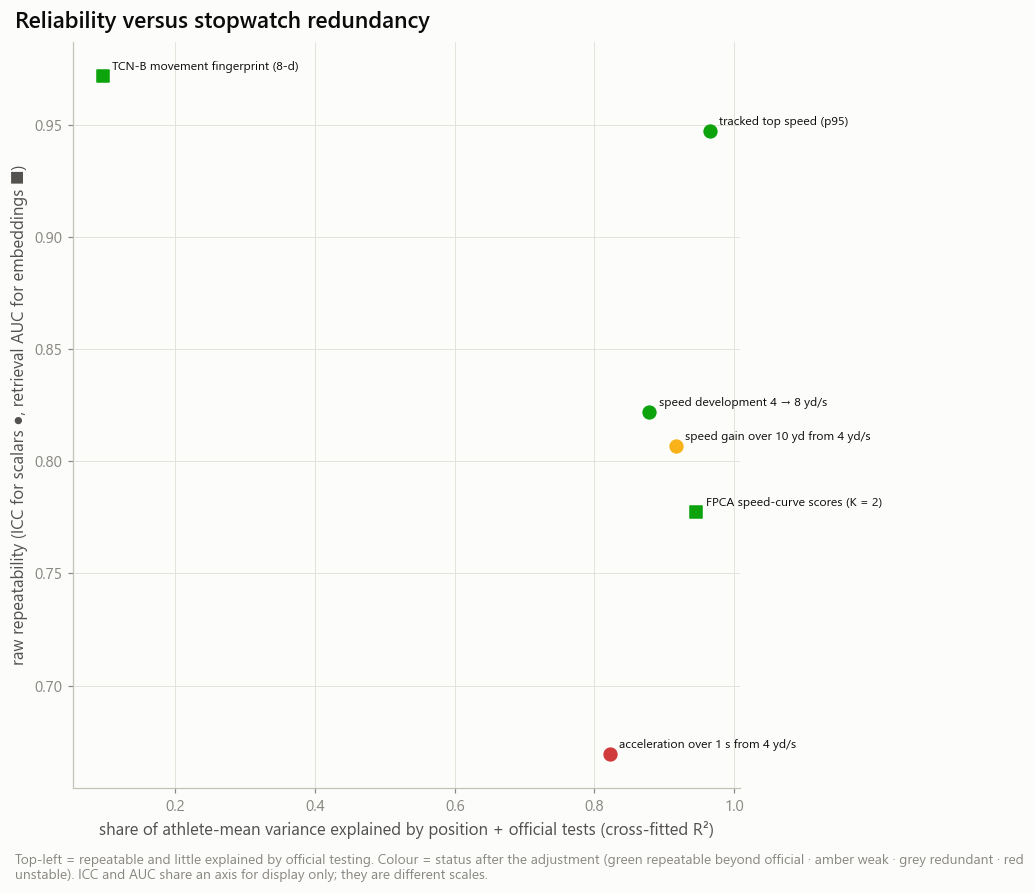

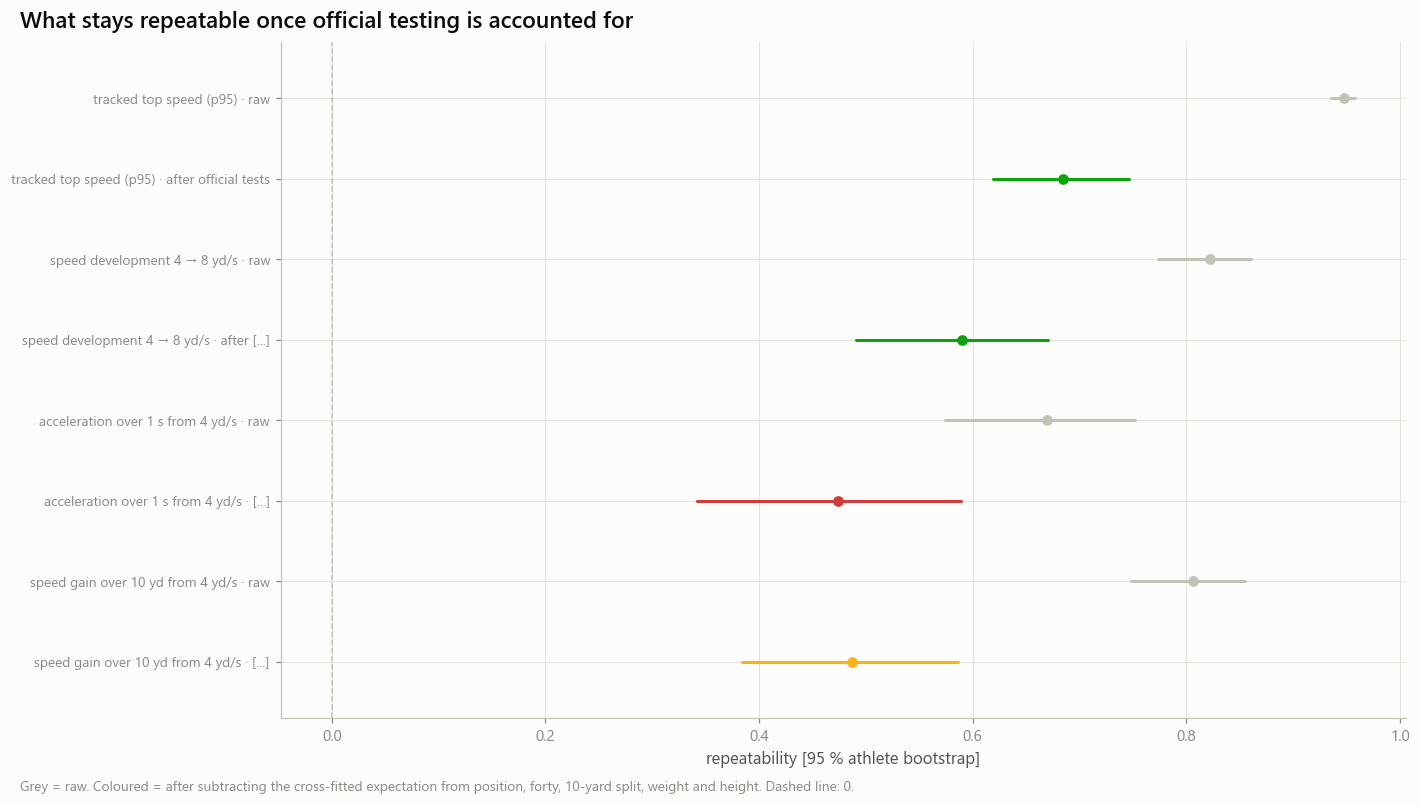

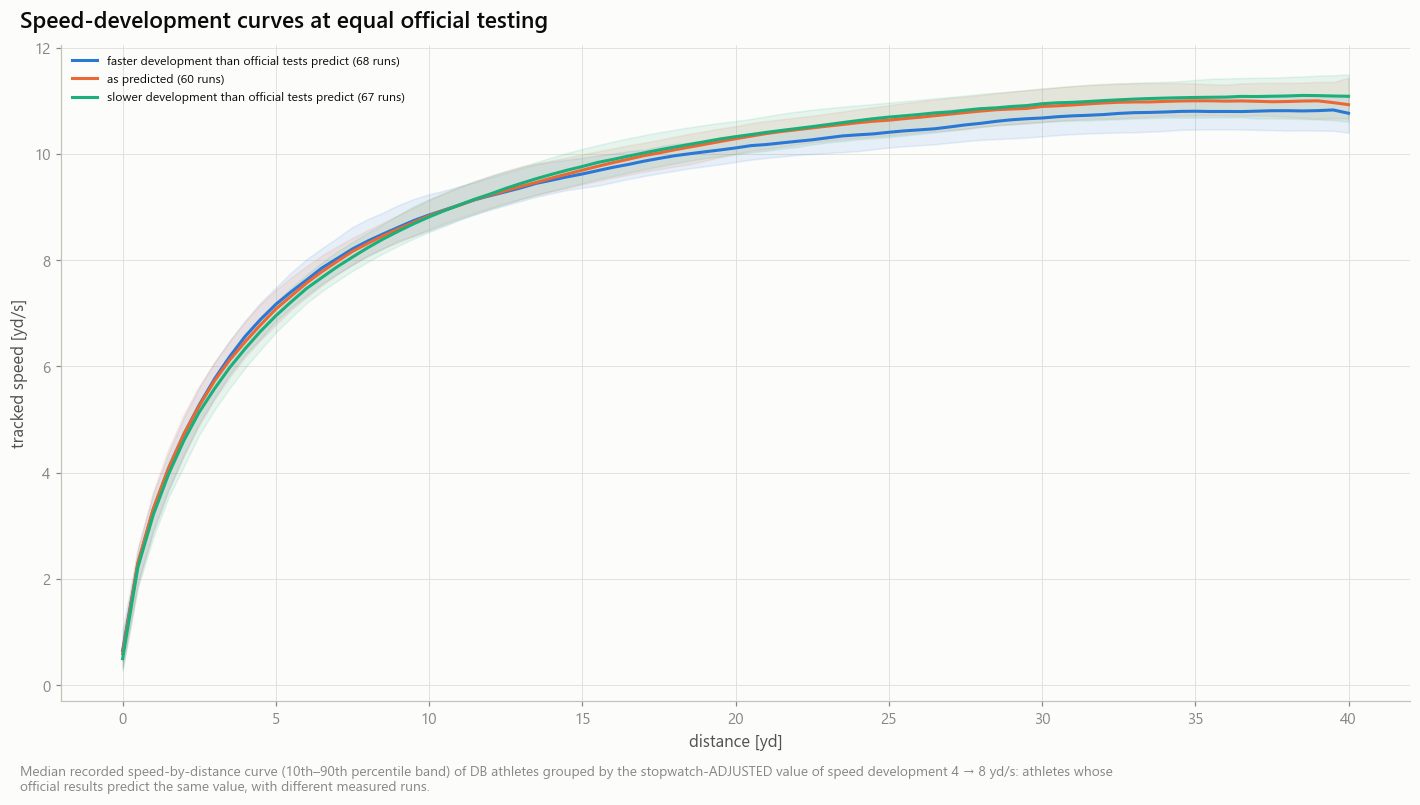

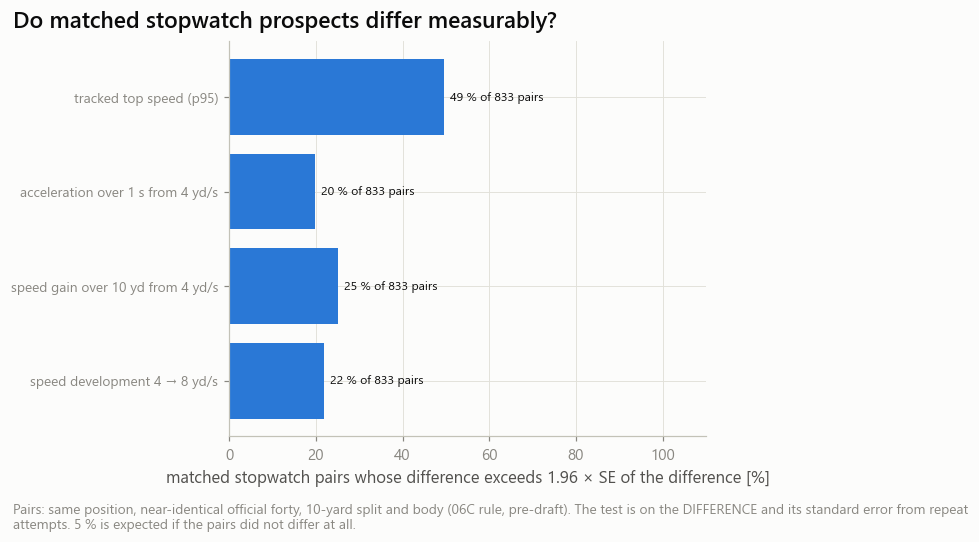

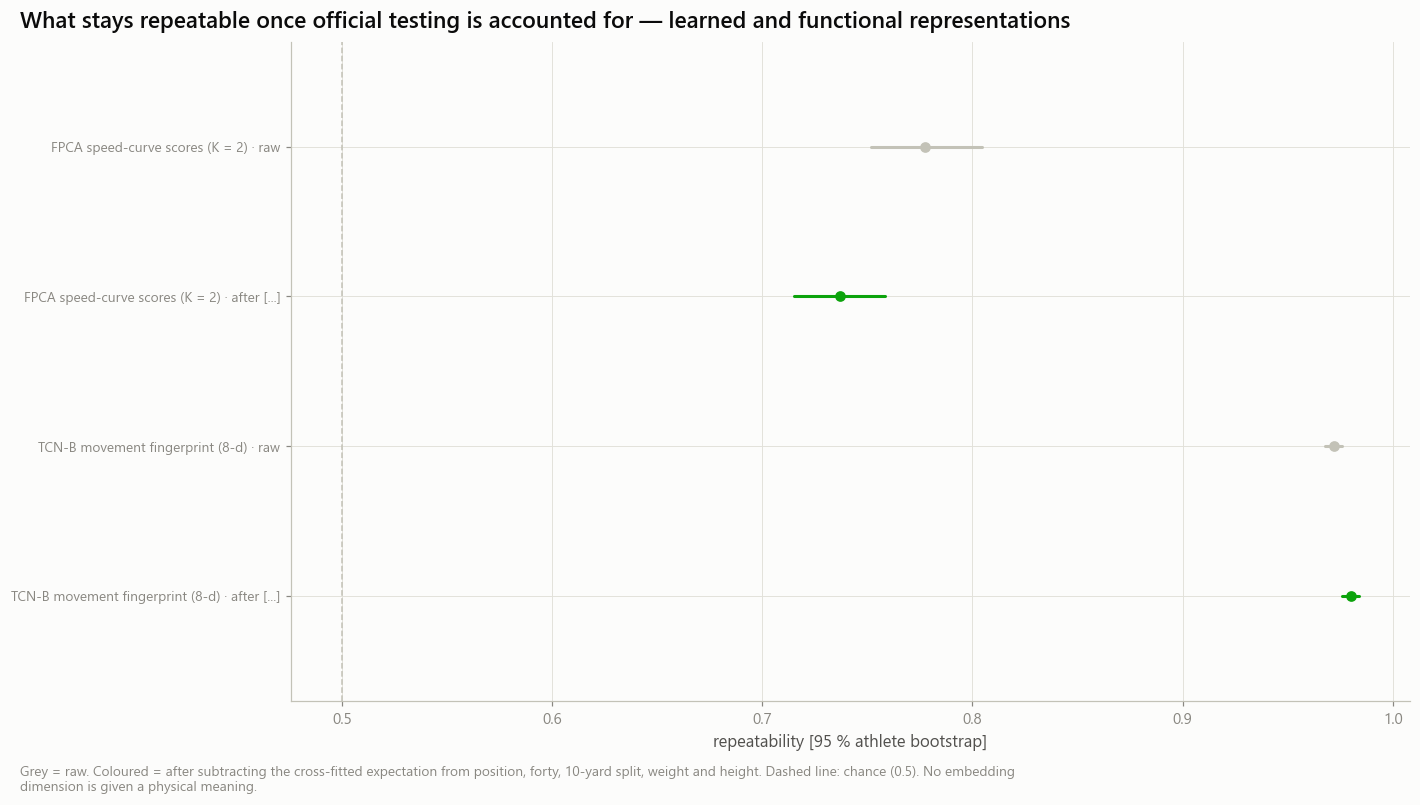

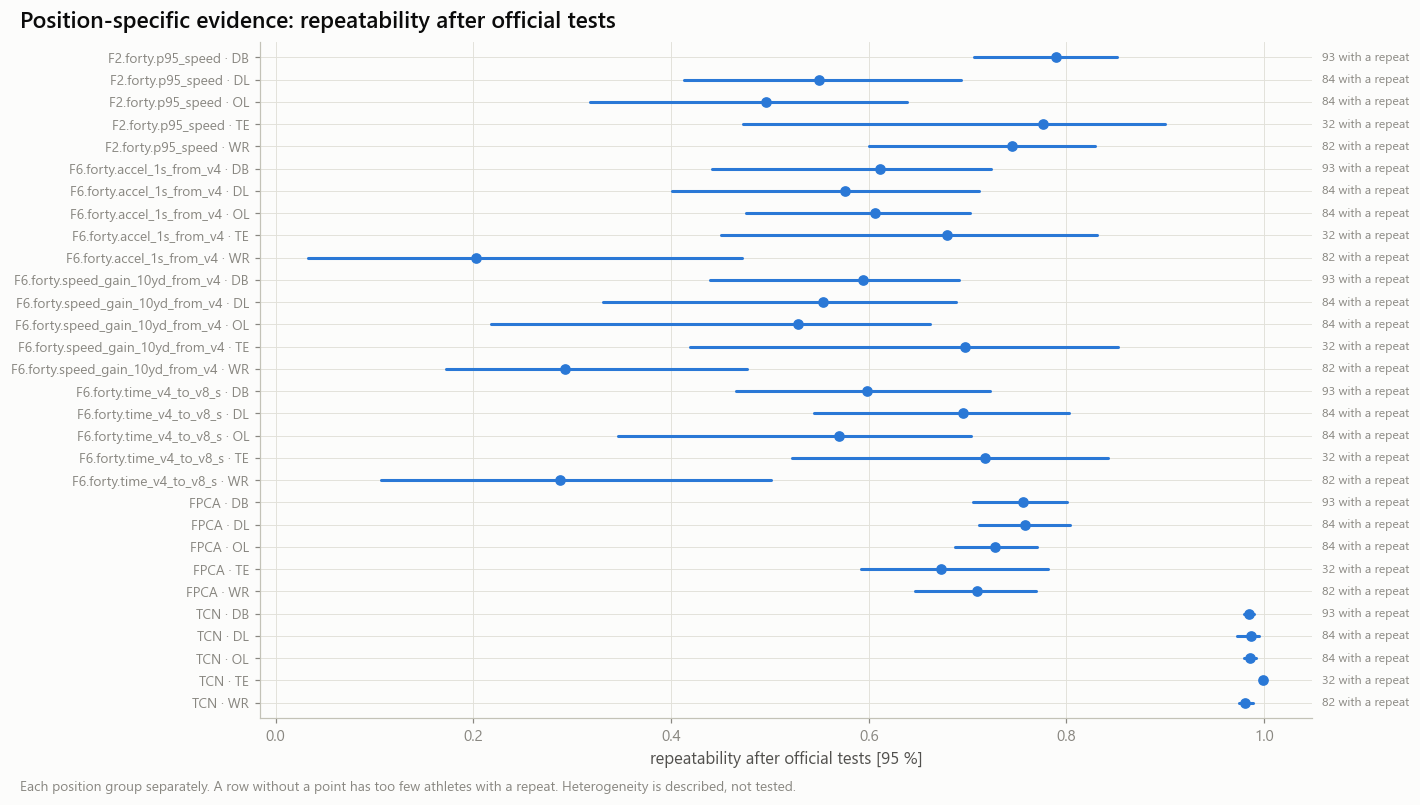

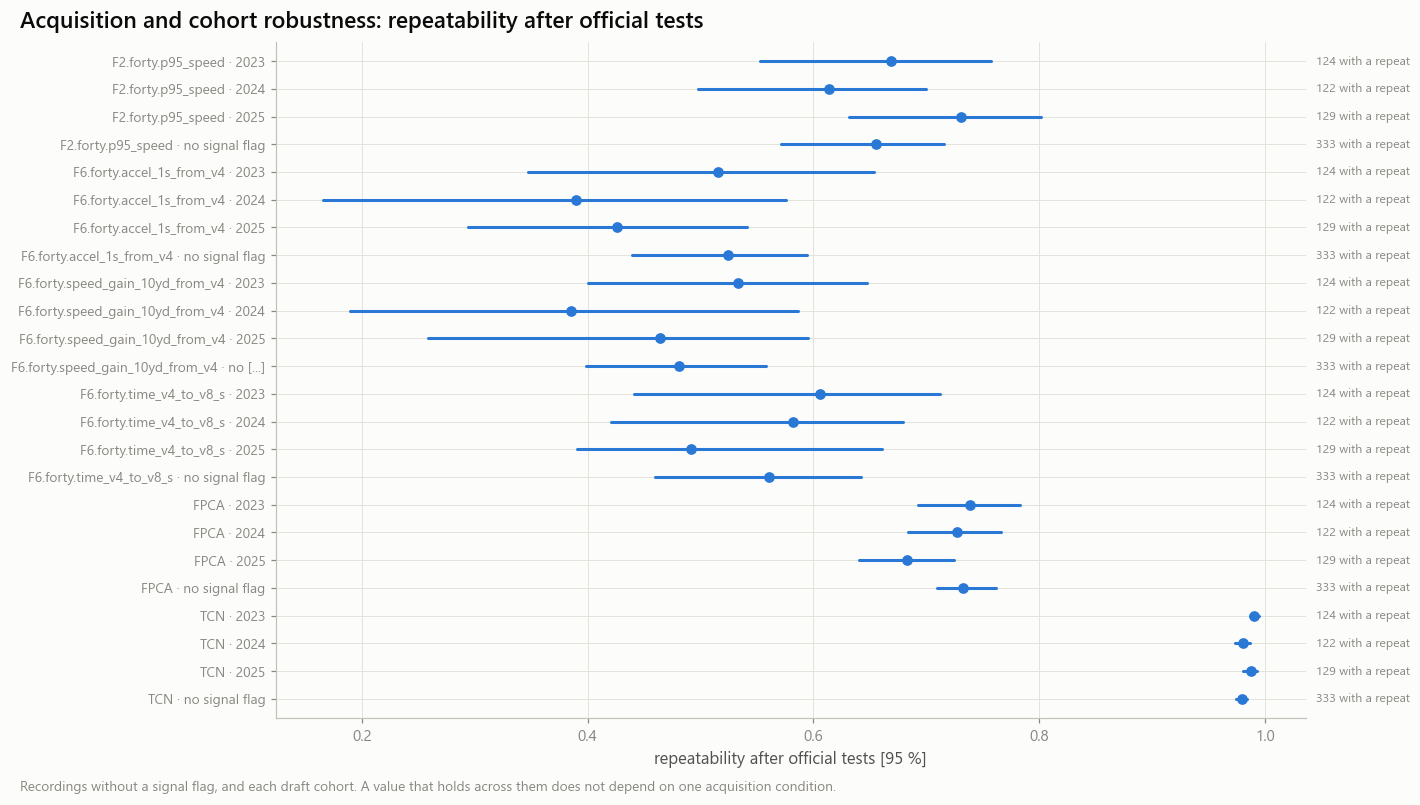

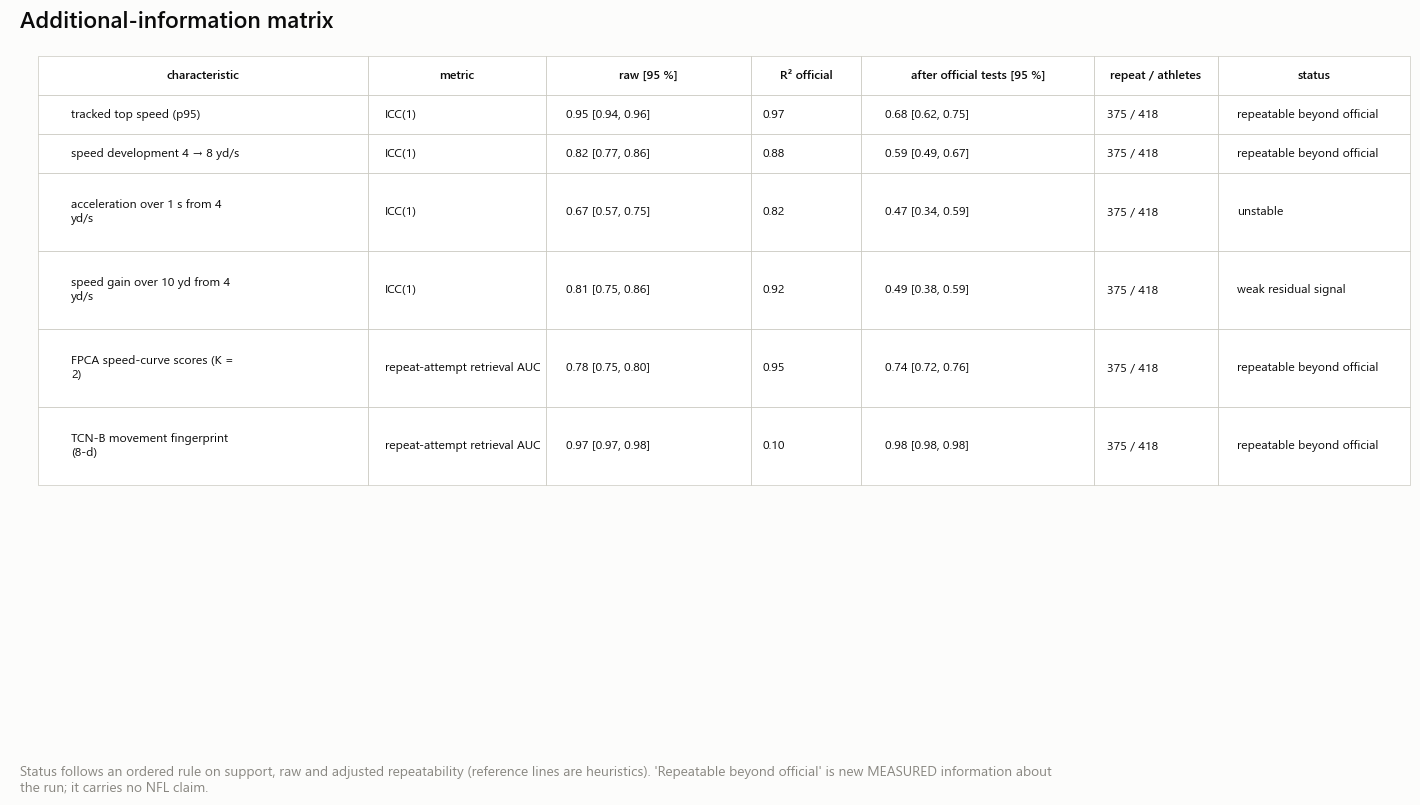

In [7]:
src, n_txt = 'movement_incremental_information', f'{roster.height} Combine athletes; athletes with a repeat per candidate in the table'
store.show(ff.fig_reliability_redundancy(info), 'AM08B4_01_reliability_versus_redundancy', {'information': info}, publication=True, source=src, n=n_txt)
store.show(ff.fig_residual_reliability(info, 'scalar'), 'AM08B4_02_residual_reliability', {'information': info}, publication=True, source=src, n=n_txt)

# speed-development curves at equal official testing: thirds of the stopwatch-adjusted 4 → 8 yd/s time, largest position
dev = residuals.filter((pl.col('feature_id') == mi.V4_V8) & pl.col('residual').is_not_null())
if frames is not None and dev.height >= 30:
    big = dev.group_by('position_group').len().sort('len', descending=True)['position_group'][0]
    g = dev.filter(pl.col('position_group') == big)
    q1, q2 = g['residual'].quantile(1 / 3), g['residual'].quantile(2 / 3)
    seq_of = attempt_values.filter((pl.col('feature_id') == mi.V4_V8) & pl.col('value').is_not_null()).select('seq_id', 'nfl_id')
    thirds = {'faster development than official tests predict': g.filter(pl.col('residual') <= q1), 'as predicted': g.filter((pl.col('residual') > q1) & (pl.col('residual') < q2)),
              'slower development than official tests predict': g.filter(pl.col('residual') >= q2)}
    groups = {name: sfig.curve_band(frames, seq_of.filter(pl.col('nfl_id').is_in(t['nfl_id'].to_list()))['seq_id'].to_list()) for name, t in thirds.items()}
    store.show(ff.fig_curve_groups(groups, big, LABELS[mi.V4_V8]), 'AM08B4_03_speed_development_curves', {'adjusted_values': g}, publication=True,
               source='sequence_frames + movement_official_adjusted_values', n=f'{g.height} {big} athletes')
else:
    print('speed-development curve figure skipped: sequence frames or adjusted values are not available')
store.show(ff.fig_matched_dist(match, LABELS), 'AM08B4_04_matched_stopwatch_athletes', {'matched': match}, publication=True, source='movement_matched_distinguishability',
           n='matched pairs per characteristic (annotated)')
store.show(ff.fig_residual_reliability(info, 'embedding'), 'AM08B4_05_tcn_residual_discrimination', {'information': info.filter(pl.col('kind') == 'embedding')},
           publication=True, source=src, n=n_txt)
store.show(ff.fig_info_subsets(sens, ['position_group'], 'Position-specific evidence: repeatability after official tests',
                               'Each position group separately. A row without a point has too few athletes with a repeat. Heterogeneity is described, not tested.'),
           'AM08B4_06_position_specific_evidence', {'sensitivity': sens}, source='movement_information_sensitivity', n='athletes with a repeat (annotated)')
store.show(ff.fig_info_subsets(sens, ['recording_quality', 'draft_cohort'], 'Acquisition and cohort robustness: repeatability after official tests',
                               'Recordings without a signal flag, and each draft cohort. A value that holds across them does not depend on one acquisition condition.'),
           'AM08B4_07_acquisition_robustness', {'sensitivity': sens}, source='movement_information_sensitivity', n='athletes with a repeat (annotated)')
store.show(ff.fig_information_matrix(info), 'AM08B4_08_additional_information_matrix', {'information': info}, publication=True, source=src, n=n_txt)

## 5 · Gate D — incremental information

Per characteristic: does it retain repeatable information beyond traditional tests? A characteristic that fails is marked **redundant** or **unstable** in the registry — the notebook does not stop, and nothing is hidden.

In [8]:
gate = save(mi.gate_d(info), mi.GATE_D)
with pl.Config(fmt_str_lengths=220, tbl_rows=-1, tbl_width_chars=280):
    display(gate.filter(pl.col('criterion') == 'repeatable_beyond_official_tests'))
text = mi.conclusions_markdown(info, match, icfg)
display(Markdown(text))
if controls.save_tables:
    (store.tables_dir / 'movement_incremental_information_conclusions.md').write_text(text, encoding='utf-8')
    store.write_json('movement_information_manifest', {
        'experiment_version': EXPERIMENT_VERSION, 'finished_at': utc_now(), 'statuses': dict(zip(info['feature_id'], info['status'])),
        'absent_candidates': ABSENT, 'football_evidence_included': FOOTBALL_HYP is not None, 'provenance': PROV})

23:41:56 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08B4] football_gate_d_information: 18 rows → warehouse/gold/advanced_movement/football_v1/football_gate_d_information.parquet


feature_id,criterion,value,passed
str,str,str,bool
"""F2.forty.p95_speed""","""repeatable_beyond_official_tests""","""residual repeatability 0.68 [0.62, 0.75] ≥ 0.50""",true
"""F6.forty.time_v4_to_v8_s""","""repeatable_beyond_official_tests""","""residual repeatability 0.59 [0.49, 0.67] ≥ 0.50""",true
"""F6.forty.accel_1s_from_v4""","""repeatable_beyond_official_tests""","""raw repeatability 0.67 below the reference line 0.70""",false
"""F6.forty.speed_gain_10yd_from_v4""","""repeatable_beyond_official_tests""","""residual repeatability 0.49 [0.38, 0.59] below 0.50""",false
"""FPCA""","""repeatable_beyond_official_tests""","""residual repeatability 0.74 [0.72, 0.76] ≥ 0.65""",true
"""TCN""","""repeatable_beyond_official_tests""","""residual repeatability 0.98 [0.98, 0.98] ≥ 0.65""",true


### 08B.4 — incremental Combine movement information

| Candidate | Metric | Raw [95 %] | R² official | After official tests [95 %] | Status |
|---|---|---|---|---|---|
| tracked top speed (p95) | ICC(1) within position | 0.95 [0.94, 0.96] | 0.97 | 0.68 [0.62, 0.75] | repeatable_beyond_official |
| speed development 4 → 8 yd/s | ICC(1) within position | 0.82 [0.77, 0.86] | 0.88 | 0.59 [0.49, 0.67] | repeatable_beyond_official |
| acceleration over 1 s from 4 yd/s | ICC(1) within position | 0.67 [0.57, 0.75] | 0.82 | 0.47 [0.34, 0.59] | unstable |
| speed gain over 10 yd from 4 yd/s | ICC(1) within position | 0.81 [0.75, 0.86] | 0.92 | 0.49 [0.38, 0.59] | weak_residual_signal |
| FPCA speed-curve scores (K = 2) | repeat-attempt retrieval AUC within position | 0.78 [0.75, 0.80] | 0.95 | 0.74 [0.72, 0.76] | repeatable_beyond_official |
| TCN-B movement fingerprint (8-d) | repeat-attempt retrieval AUC within position | 0.97 [0.97, 0.98] | 0.10 | 0.98 [0.98, 0.98] | repeatable_beyond_official |

- `F2.forty.p95_speed`: 49.46 % of 833 matched stopwatch pairs differ by more than their measurement error
- `F6.forty.accel_1s_from_v4`: 19.81 % of 833 matched stopwatch pairs differ by more than their measurement error
- `F6.forty.speed_gain_10yd_from_v4`: 25.09 % of 833 matched stopwatch pairs differ by more than their measurement error
- `F6.forty.time_v4_to_v8_s`: 21.85 % of 833 matched stopwatch pairs differ by more than their measurement error

Reference lines (heuristics): scalar raw ICC ≥ 0.70, residual ICC ≥ 0.50 with a positive lower bound; embedding raw AUC ≥ 0.75, residual AUC ≥ 0.65 with a lower bound above 0.5. Repeatable beyond the stopwatch means NEW MEASURED INFORMATION about the athlete's run — it says nothing about NFL performance.

## 6 · Reading

- *Repeatable beyond official tests* means **new measured information about the athlete's run**. It carries no claim about NFL performance: that claim lives in the transfer notebooks and is read from their tables.
- *Redundant with official tests* is a useful result: the stopwatch already tells the scout this.
- The TCN-B fingerprint is a similarity space. Its residual AUC says whether an athlete is still recognisable among athletes with the same official results — nothing about what the dimensions mean.

**Send back:** the checks table, the information table with reasons, the sensitivity table, the matched table, the registry, figures `AM08B4_01`, `02`, `05`, `08`.

**Next:** `08b5_scouting_decision_intelligence.ipynb`.